<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/%C3%B6dev6g%C3%B6rev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Orijinal Resim:


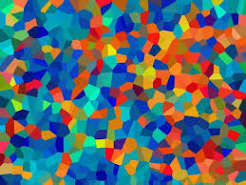

Canny + Median Filtre Çıkışı:


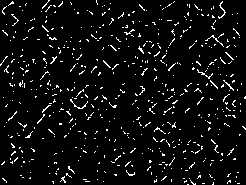

Standart Hough Dönüşümü (Kırmızı):


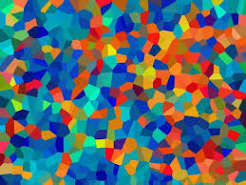

Olasılıksal Hough Dönüşümü (Yeşil):


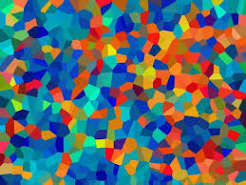

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

# 1. Resmi yükleme ve gri tonlamaya çevirme
img = cv2.imread("indir.jpg")
if img is None:
  print(
      "Resim yüklenemedi. Lütfen dosya adını ve sol paneldeki yüklemeyi"
      " kontrol edin."
  )
else:
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

  # 2. Canny Kenar Algılama
  edges = cv2.Canny(gray, 50, 150, apertureSize=3)

  # 3. Median Filtre Uygulama
  median_edges = cv2.medianBlur(edges, 3)

  # Çizimleri üzerine yapabilmek için orijinal resmin kopyaları
  img_standard = img.copy()
  img_probabilistic = img.copy()

  # 4. İlk Test: Standart Hough Dönüşümü (cv2.HoughLines)
  lines = cv2.HoughLines(median_edges, 1, np.pi / 180, 150)

  if lines is not None:
    for line in lines:
      rho, theta = line[0]
      a = np.cos(theta)
      b = np.sin(theta)
      x0 = a * rho
      y0 = b * rho
      x1 = int(x0 + 1000 * (-b))
      y1 = int(y0 + 1000 * (a))
      x2 = int(x0 - 1000 * (-b))
      y2 = int(y0 - 1000 * (a))
      # Standart Hough doğruları için KIRMIZI renk (BGR: 0, 0, 255)
      cv2.line(img_standard, (x1, y1), (x2, y2), (0, 0, 255), 2)

  # 5. İkinci Test: Olasılıksal Hough Dönüşümü (cv2.HoughLinesP)
  linesP = cv2.HoughLinesP(
      median_edges, 1, np.pi / 180, 50, minLineLength=50, maxLineGap=10
  )

  if linesP is not None:
    for line in linesP:
      x1, y1, x2, y2 = line[0]
      # Olasılıksal Hough doğruları için YEŞİL renk (BGR: 0, 255, 0)
      cv2.line(img_probabilistic, (x1, y1), (x2, y2), (0, 255, 0), 2)

  # Colab ortamında görüntüleri listeleme (cv2_imshow kullanarak)
  print("Orijinal Resim:")
  cv2_imshow(img)

  print("Canny + Median Filtre Çıkışı:")
  cv2_imshow(median_edges)

  print("Standart Hough Dönüşümü (Kırmızı):")
  cv2_imshow(img_standard)

  print("Olasılıksal Hough Dönüşümü (Yeşil):")
  cv2_imshow(img_probabilistic)